# Imports

Needs to run xenicsEnv (Python 3.9.13)

In [1]:
import numpy as np

import matplotlib
matplotlib.rc_file('D:\\Active_PIC\\matplotlibrc')
matplotlib.use("TkAgg")
import matplotlib.pyplot as plt
import matplotlib.colors as colors
from matplotlib.colors import ListedColormap
%matplotlib inline

import os, sys
sys.path.append('D://Active_PIC//ControlCode//HardwareLib//')
import importlib

import Bench
import KeysightE36312A

import logging
logging.basicConfig(level=logging.DEBUG,
                    format='%(name)-12s: %(levelname)-8s %(message)s',
                    handlers=[logging.StreamHandler(sys.stdout)],
                   )
logging.getLogger('matplotlib').setLevel(logging.WARNING)

# Connect to hardware

Notes:
- Connecting to Zaber actuators/stages:
    - Axis 0: camera x (horizontal) motion = `Zaber.CAM_X`
        - Increasing values move camera away from user/top of chip.
        - Camera image is horizontally flipped (plotted with pcolormesh), i.e. moving the camera towards the user moves the image to the right.
    - Axis 1: camera focus motion = `Zaber.CAM_FOCUS`
    - Axis 2: camera y (vertical) motion = `Zaber.CAM_Y`. Has a tendency to slip/stall; first try motion as is, and if exception is raised, move at 0.1 mm/s
        - Increasing values move camera up.
        - Camera image is vertically flipped (plotted with pcolormesh), i.e. moving the camera up moves the image up.

In [6]:
bench = Bench.BENCH(keysight=False)

TLX2        : INFO     Connected to TLX2 laser.
TLX2        : DEBUG    VOA on, set to 20.0 dB.
TLX2        : DEBUG    VOA set to 20.0 dB.
XenicsCam   : INFO     Device[0] XEVA-CL-FPA-2.5-320-TE4-60Hz @  (USB)
XenicsCam   : INFO     URL: cam://0
XenicsCam   : INFO     State: Available (0)

XenicsCam   : INFO     Checking camera temperature
XenicsCam   : INFO     CCD is cold! Now available to take images!
XenicsCam   : INFO     Exposure time was 2500.0 μs
XenicsCam   : INFO     Exposure time is now 100.0 μs
XDAC        : DEBUG    ------------------------------------------
Chosen XDAC address: 169.254.54.201
------------------------------------------

XDAC        : INFO     XDAC sockets created!
XDAC        : INFO     Unlocking connection to XDAC...
XDAC        : DEBUG    Sent XDAC command: "GETINFO:nicslab".
XDAC        : DEBUG    XDAC answer = {OK:120:20:U:1}
XDAC        : INFO     Setting XDAC channel ranges...
XDAC        : DEBUG    Sent XDAC command: "SETRV:1:2".
XDAC        : DEBUG 

Take a reference image

XDAC        : DEBUG    Sent XDAC command: "SETV:61:9.000".
XDAC        : DEBUG    XDAC answer = {9.000}
XDAC        : DEBUG    Channel 61 set to 9.0 V.
XDAC        : DEBUG    Sent XDAC command: "SETV:62:9.000".
XDAC        : DEBUG    XDAC answer = {9.000}
XDAC        : DEBUG    Channel 62 set to 9.0 V.
TLX2        : DEBUG    VOA set to 20.0 dB.
XDAC        : DEBUG    Sent XDAC command: "SETV:60:4.482".
XDAC        : DEBUG    XDAC answer = {4.482}
XDAC        : DEBUG    Channel 60 set to 4.482033077736424 V.
XDAC        : DEBUG    Sent XDAC command: "SETV:41:6.000".
XDAC        : DEBUG    XDAC answer = {6.000}
XDAC        : DEBUG    Channel 41 set to 6.0 V.


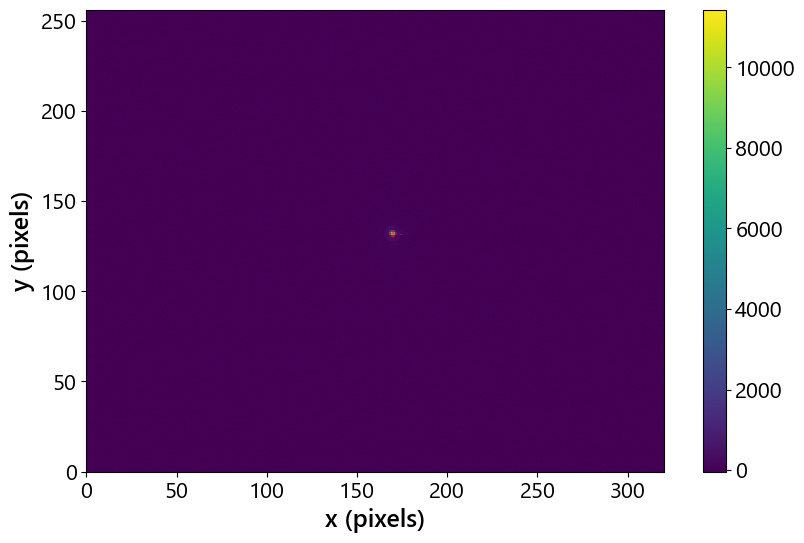

TLX2        : DEBUG    VOA set to 20.0 dB.
XDAC        : DEBUG    Sent XDAC command: "SETV:60:4.386".
XDAC        : DEBUG    XDAC answer = {4.386}
XDAC        : DEBUG    Channel 60 set to 4.386331195632968 V.
TLX2        : DEBUG    VOA set to 20.0 dB.
XDAC        : DEBUG    Sent XDAC command: "SETV:60:4.447".
XDAC        : DEBUG    XDAC answer = {4.447}
XDAC        : DEBUG    Channel 60 set to 4.447108627686814 V.
TLX2        : DEBUG    VOA set to 20.0 dB.
XDAC        : DEBUG    Sent XDAC command: "SETV:60:4.600".
XDAC        : DEBUG    XDAC answer = {4.600}
XDAC        : DEBUG    Channel 60 set to 4.6000000000000005 V.


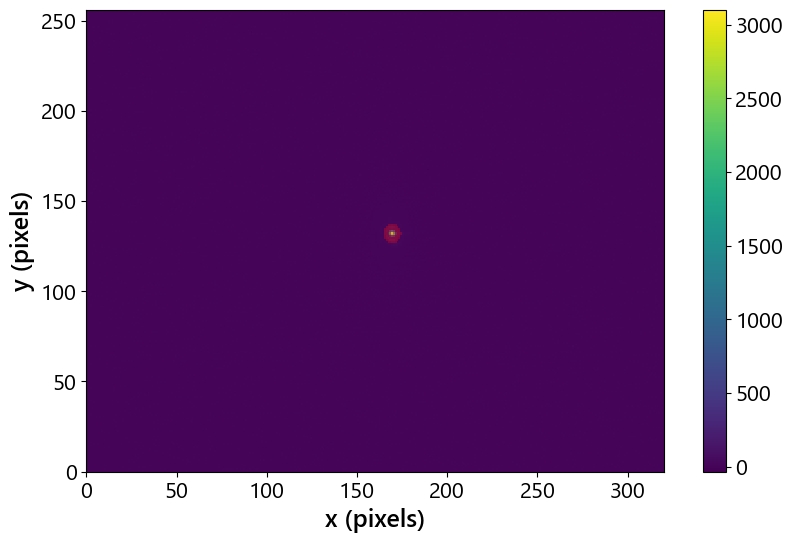

XDAC        : DEBUG    Sent XDAC command: "MEASV:60".
XDAC        : DEBUG    XDAC answer = {4.60273}
XDAC        : DEBUG    Sent XDAC command: "MEASC:60".
XDAC        : DEBUG    XDAC answer = {0.02438}


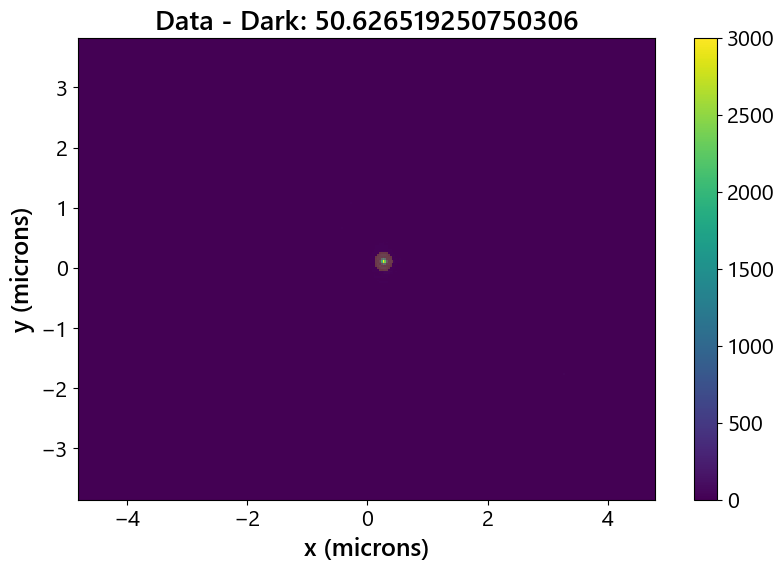

In [3]:
# Set XPOW voltages for reference image
bench.num_outputs = 1
bench.xcom.apply_voltage(61, 9.0)
bench.xcom.apply_voltage(62, 9.0)
bench.set_VOA(50)

# phase_voltages = np.linspace(3.5, 5, 11)

# for phase_voltage in phase_voltages[:1]:
#     bench.keysight.set_voltage(phase_voltage, 3)

bench.apply_voltage(41, 6.0)
_, _, data, _ = bench.cam.take_image(navg=1)
bench.coords = bench.find_output_centers(data-bench.dark, bench.num_outputs)
atten, data, timestamp = bench.attenuation_adjust(bench.coords[0], 45, navg=1, stack=True)
_, _, data, timestamp = bench.cam.take_image(stack=True)

bench.masks = bench.build_output_mask(data-bench.dark, bench.num_outputs, coords=bench.coords)
data_reduce = data - bench.dark

# Plot the reference data with the output mask

fig, ax = plt.subplots(1, 1, figsize=(10,6))
yellow_cmap = ListedColormap(['yellow'])
vmax = 3000
cbar_norm = colors.Normalize(vmin=0, vmax=vmax)  
im = ax.pcolormesh(bench.x, bench.y, data_reduce, norm=cbar_norm, zorder=0)
for mask in bench.masks:
    masked_overlay = np.ma.masked_where(~mask, np.ones_like(mask))
    ax.pcolormesh(bench.x, bench.y, masked_overlay, cmap=yellow_cmap, alpha=0.2, zorder=1)
fig.colorbar(im, ax=ax, fraction=0.05*bench.y_dim/bench.x_dim)
ax.set_xlabel('x (microns)', fontsize=18)
ax.set_ylabel('y (microns)', fontsize=18)
ax.set_title(f'Data - Dark: {bench.get_VOA()}')
ax.set_aspect('equal')
plt.show()

In [16]:
bench.close()

TLX2        : DEBUG    Laser set to off.
TLX2        : DEBUG    Laser tuned to channel 45, 1589.9892 nm.
TLX2        : DEBUG    Fine tuning offset set to 0 MHz, now at 1589.9892 nm.
TLX2        : DEBUG    Laser set to off.
TLX2        : INFO     Connection to TLX2 laser closed.
TEC         : INFO     Temperature control loop off.
TEC         : INFO     Temperature control loop off.
Connection to Arduino closed.
Zaber       : INFO     Connection to Zabers closed.
XenicsCam   : INFO     Stopped streaming frames!
XenicsCam   : INFO     Camera closed!
XDAC        : DEBUG    Sent XDAC command: "ZERO:ALL".
XDAC        : DEBUG    XDAC answer = {OK}
XDAC        : DEBUG    Sent XDAC command: "SETMULTIA;;:C1:150.000:C2:150.000:C3:150.000:C4:150.000:C5:150.000:C6:150.000:C7:150.000:C8:150.000:C9:150.000:C10:150.000:C11:150.000:C12:150.000:C13:150.000:C14:150.000:C15:150.000:C16:150.000:C17:150.000:C18:150.000:C19:150.000:C20:150.000:C21:150.000:C22:150.000:C23:150.000:C24:150.000:C25:150.000:C26:

In [38]:
bench.tec.read_temperature()

# Livestream photometry

In [54]:
def crop_with_padding(frame, mask, pad=5):
    ys, xs = np.where(mask)

    y0, y1 = ys.min(), ys.max()
    x0, x1 = xs.min(), xs.max()

    y0 = max(y0 - pad, 0)
    y1 = min(y1 + pad, frame.shape[0] - 1)
    x0 = max(x0 - pad, 0)
    x1 = min(x1 + pad, frame.shape[1] - 1)

    cropped_frame = frame[y0:y1+1, x0:x1+1]
    cropped_mask = mask[y0:y1+1, x0:x1+1]

    return cropped_frame, cropped_mask, (y0, x0)

# def extract_fixed_roi(frame, mask, yc, xc, h, w):

#     H, W = frame.shape

#     y0 = yc - h // 2
#     x0 = xc - w // 2
#     y1 = y0 + h
#     x1 = x0 + w

#     cropped = np.zeros((h, w))
#     cropped_mask = np.zeros((h, w), dtype=bool)

#     yy0 = max(0, y0)
#     yy1 = min(H, y1)
#     xx0 = max(0, x0)
#     xx1 = min(W, x1)

#     cy0 = yy0 - y0
#     cx0 = xx0 - x0

#     cropped[cy0:cy0 + (yy1 - yy0), cx0:cx0 + (xx1 - xx0)] = frame[yy0:yy1, xx0:xx1]
#     cropped_mask[cy0:cy0 + (yy1 - yy0), cx0:cx0 + (xx1 - xx0)] = mask[yy0:yy1, xx0:xx1]

#     return cropped, cropped_mask

def live_view_outputs(bench, masks, interval=0.2, vmin=0, vmax=12000):

    import numpy as np
    import matplotlib
    matplotlib.use("TkAgg", force=True)
    import matplotlib.pyplot as plt

    running = {"go": True}
    def stop_stream():
        running["go"] = False
    globals()["stop_stream"] = stop_stream

    take_image = bench.cam.take_image
    dark = bench.dark

    num_outputs = len(masks)

    frame = take_image()[2] - dark

    # -------------------------------------------------------
    # tight bounding boxes ONLY (no padding anywhere)
    # -------------------------------------------------------
    rois = []
    centers = []

    for m in masks:
        ys, xs = np.where(m)

        y0, y1 = ys.min(), ys.max() + 1
        x0, x1 = xs.min(), xs.max() + 1

        rois.append((y0, y1, x0, x1))
        centers.append((int(np.mean(ys)), int(np.mean(xs))))

    # -------------------------------------------------------
    cmap = plt.cm.viridis.copy()
    cmap.set_bad("gray")

    fig, axes = plt.subplots(num_outputs, 2, figsize=(8, 3*num_outputs))
    if num_outputs == 1:
        axes = np.array([axes])

    ims = []
    text_boxes = []
    prof_lines = []

    for i in range(num_outputs):

        ax_img, ax_prof = axes[i]
        y0, y1, x0, x1 = rois[i]

        crop = frame[y0:y1, x0:x1]
        msk = masks[i][y0:y1, x0:x1]

        display = np.where(msk, crop, np.nan)

        im = ax_img.imshow(
            display,
            origin="lower",
            aspect="equal",
            cmap=cmap,
            vmin=vmin,
            vmax=vmax
        )

        ims.append(im)
        ax_img.set_axis_off()

        txt = ax_img.text(
            0.02, 0.90, "",
            transform=ax_img.transAxes,
            color="white"
        )
        text_boxes.append(txt)

        x = np.arange(crop.shape[1])
        line, = ax_prof.plot(x, np.zeros_like(x))
        prof_lines.append((ax_prof, line))

        ax_prof.set_ylim(vmin, vmax)
        ax_prof.set_title("Crosscut")

    plt.tight_layout()
    plt.show(block=False)

    print("Streaming started. Run stop_stream() to stop.")

    # -------------------------------------------------------
    # LOOP
    # -------------------------------------------------------
    while running["go"] and plt.fignum_exists(fig.number):

        frame = take_image()[2] - dark

        for i in range(num_outputs):

            y0, y1, x0, x1 = rois[i]

            crop = frame[y0:y1, x0:x1]
            msk = masks[i][y0:y1, x0:x1]

            display = np.where(msk, crop, np.nan)

            ims[i].set_data(display)

            vals = crop[msk]
            max_val = np.max(vals) if vals.size else np.nan
            text_boxes[i].set_text(f"max: {max_val:.0f}")

            weighted = np.where(msk, crop, -np.inf)
            y_max = np.argmax(np.max(weighted, axis=1))

            profile = crop[y_max, :]

            prof_lines[i][1].set_data(np.arange(profile.size), profile)

        fig.canvas.draw_idle()
        plt.pause(interval)

    plt.close(fig)

In [12]:
def live_view_outputs(bench, masks, interval=0.2, vmin=0, vmax=12000):

    import numpy as np
    import matplotlib
    matplotlib.use("TkAgg", force=True)
    import matplotlib.pyplot as plt

    running = {"go": True}
    def stop_stream():
        running["go"] = False
    globals()["stop_stream"] = stop_stream

    take_image = bench.cam.take_image
    dark = bench.dark

    num_outputs = len(masks)

    # -------------------------------------------------------
    # ROI + PRECOMPUTE MASK INDICES (BIG SPEEDUP)
    # -------------------------------------------------------
    rois = []
    mask_idx = []
    roi_shapes = []

    for m in masks:
        ys, xs = np.where(m)

        y0, y1 = ys.min(), ys.max() + 1
        x0, x1 = xs.min(), xs.max() + 1

        rois.append((y0, y1, x0, x1))

        h, w = y1 - y0, x1 - x0
        roi_shapes.append((h, w))

        mask_idx.append(np.flatnonzero(m[y0:y1, x0:x1]))

    # -------------------------------------------------------
    cmap = plt.cm.viridis.copy()
    cmap.set_bad("gray")

    fig, axes = plt.subplots(num_outputs, 2, figsize=(8, 3*num_outputs))
    if num_outputs == 1:
        axes = np.array([axes])

    ims = []
    text_boxes = []
    prof_lines = []

    for i in range(num_outputs):

        ax_img, ax_prof = axes[i]
        h, w = roi_shapes[i]

        im = ax_img.imshow(
            np.zeros((h, w)),
            origin="lower",
            aspect="equal",
            cmap=cmap,
            vmin=vmin,
            vmax=vmax
        )

        ims.append(im)
        ax_img.set_axis_off()

        txt = ax_img.text(0.02, 0.90, "", transform=ax_img.transAxes, color="white")
        text_boxes.append(txt)

        x = np.arange(w)
        line, = ax_prof.plot(x, np.zeros(w))
        prof_lines.append((ax_prof, line))
        ax_prof.axhline(5*np.std(bench.dark), linestyle='dashed', color='gray')

        ax_prof.set_ylim(vmin, vmax)
        ax_prof.set_title("Crosscut")

    plt.tight_layout()
    plt.show(block=False)

    print("Streaming started. Run stop_stream() to stop.")

    # -------------------------------------------------------
    # LOOP (FAST PATH)
    # -------------------------------------------------------
    while running["go"] and plt.fignum_exists(fig.number):

        frame = take_image()[2] - dark

        for i in range(num_outputs):

            y0, y1, x0, x1 = rois[i]
            crop = frame[y0:y1, x0:x1]

            mflat = mask_idx[i]
            cflat = crop.ravel()

            # ---------------------------
            # MAX (fast indexed version)
            # ---------------------------
            if mflat.size:
                vals = cflat[mflat]
                max_val = np.max(vals)
            else:
                max_val = np.nan

            text_boxes[i].set_text(f"max: {max_val:.0f}")

            # ---------------------------
            # CROSSCUT (fast row reduction)
            # ---------------------------
            row_max = np.max(crop, axis=1)
            y_max = np.argmax(row_max)
            profile = crop[y_max, :]

            ims[i].set_data(crop)
            prof_lines[i][1].set_data(np.arange(profile.size), profile)

        fig.canvas.draw_idle()
        plt.pause(interval)

    plt.close(fig)

In [12]:
bench.tec.on()

TEC         : INFO     Temperature control loop on.


In [7]:
bench.close()

TLX2        : DEBUG    Laser set to off.
TLX2        : DEBUG    Laser tuned to channel 45, 1589.9892 nm.
TLX2        : DEBUG    Fine tuning offset set to 0 MHz, now at 1589.9892 nm.
TLX2        : DEBUG    Laser set to off.
TLX2        : INFO     Connection to TLX2 laser closed.
TEC         : INFO     Temperature control loop off.
TEC         : INFO     Temperature control loop off.
Connection to Arduino closed.
Zaber       : INFO     Connection to Zabers closed.
XenicsCam   : INFO     Stopped streaming frames!
XenicsCam   : INFO     Camera closed!
XDAC        : DEBUG    Sent XDAC command: "ZERO:ALL".
XDAC        : DEBUG    XDAC answer = {OK}
XDAC        : DEBUG    Sent XDAC command: "SETMULTIA;;:C1:150.000:C2:150.000:C3:150.000:C4:150.000:C5:150.000:C6:150.000:C7:150.000:C8:150.000:C9:150.000:C10:150.000:C11:150.000:C12:150.000:C13:150.000:C14:150.000:C15:150.000:C16:150.000:C17:150.000:C18:150.000:C19:150.000:C20:150.000:C21:150.000:C22:150.000:C23:150.000:C24:150.000:C25:150.000:C26:

In [33]:
bench.set_VOA(14)
live_view_outputs(
    bench,
    bench.masks
)

TLX2        : DEBUG    VOA set to 14.0 dB.
XPOW        : DEBUG    Sent XPOW command: "CH:20:VOLT:0" to port "COM6".
XPOW        : DEBUG    COM6answer = {:20:VOLT:0:OK}
XPOW        : DEBUG    Sent XPOW command: "CH:20:VAL?" to port "COM6".
XPOW        : DEBUG    COM6answer = {20:0.000:0.0000}
XPOW        : DEBUG    Channel 60 set to 0 V.
PIL.PngImagePlugin: DEBUG    STREAM b'IHDR' 16 13
PIL.PngImagePlugin: DEBUG    STREAM b'sBIT' 41 4
PIL.PngImagePlugin: DEBUG    b'sBIT' 41 4 (unknown)
PIL.PngImagePlugin: DEBUG    STREAM b'pHYs' 57 9
PIL.PngImagePlugin: DEBUG    STREAM b'IDAT' 78 374
PIL.PngImagePlugin: DEBUG    STREAM b'IHDR' 16 13
PIL.PngImagePlugin: DEBUG    STREAM b'sBIT' 41 4
PIL.PngImagePlugin: DEBUG    b'sBIT' 41 4 (unknown)
PIL.PngImagePlugin: DEBUG    STREAM b'pHYs' 57 9
PIL.PngImagePlugin: DEBUG    STREAM b'IDAT' 78 286
PIL.PngImagePlugin: DEBUG    STREAM b'IHDR' 16 13
PIL.PngImagePlugin: DEBUG    STREAM b'sBIT' 41 4
PIL.PngImagePlugin: DEBUG    b'sBIT' 41 4 (unknown)
PIL.PngI

In [10]:
bench.tlx.laser_on()

TLX2        : DEBUG    Laser set to on. VOA is 20.0.


In [34]:
bench.close()

TLX2        : DEBUG    Laser set to off.
TLX2        : DEBUG    Laser set to off.
TLX2        : INFO     Connection to TLX2 laser closed.
TEC         : INFO     Temperature control loop off.
TEC         : INFO     Temperature control loop off.
Connection to Arduino closed.
Zaber       : INFO     Connection to Zabers closed.
XenicsCam   : INFO     Stopped streaming frames!
XenicsCam   : INFO     Camera closed!
XPOW        : DEBUG    Sent XPOW command: "CH:1:VOLT:0" to port "COM4".
XPOW        : DEBUG    COM4answer = {:1:VOLT:0:OK}
XPOW        : DEBUG    Sent XPOW command: "CH:1:CUR:200" to port "COM4".
XPOW        : DEBUG    COM4answer = {1:CUR:200:OK}
XPOW        : DEBUG    Sent XPOW command: "CH:2:VOLT:0" to port "COM4".
XPOW        : DEBUG    COM4answer = {:2:VOLT:0:OK}
XPOW        : DEBUG    Sent XPOW command: "CH:2:CUR:200" to port "COM4".
XPOW        : DEBUG    COM4answer = {2:CUR:200:OK}
XPOW        : DEBUG    Sent XPOW command: "CH:3:VOLT:0" to port "COM4".
XPOW        : DEBUG  

# Nelder-Mead search

In [13]:
bench.tec.read_temperature()

17.86

XDAC        : DEBUG    Sent XDAC command: "SETV:68:9.100".
XDAC        : DEBUG    XDAC answer = {9.100}
XDAC        : DEBUG    Channel 68 set to 9.1 V.
KeysightE36312A: DEBUG    Channel 3 voltage set to 9.042977 V.
KeysightE36312A: DEBUG    Channel 2 voltage set to 4.841079 V.
TLX2        : DEBUG    VOA set to 20.0 dB.
XDAC        : DEBUG    Sent XDAC command: "SETV:60:3.674".
XDAC        : DEBUG    XDAC answer = {3.674}
XDAC        : DEBUG    Channel 60 set to 3.673824949138076 V.
TLX2        : DEBUG    VOA set to 20.0 dB.
XDAC        : DEBUG    Sent XDAC command: "SETV:60:3.821".
XDAC        : DEBUG    XDAC answer = {3.821}
XDAC        : DEBUG    Channel 60 set to 3.8209618735321103 V.
Bench       : INFO     voltages:[9.04478587 4.83916498]
Bench       : INFO     Null mode intensities: [8.3524755e+10]
Bench       : INFO     Side mode intensities: 1
Bench       : INFO     Null: [109.21815] dB
Bench       : INFO     

KeysightE36312A: DEBUG    Channel 3 voltage set to 9.168233 V.
Keysi

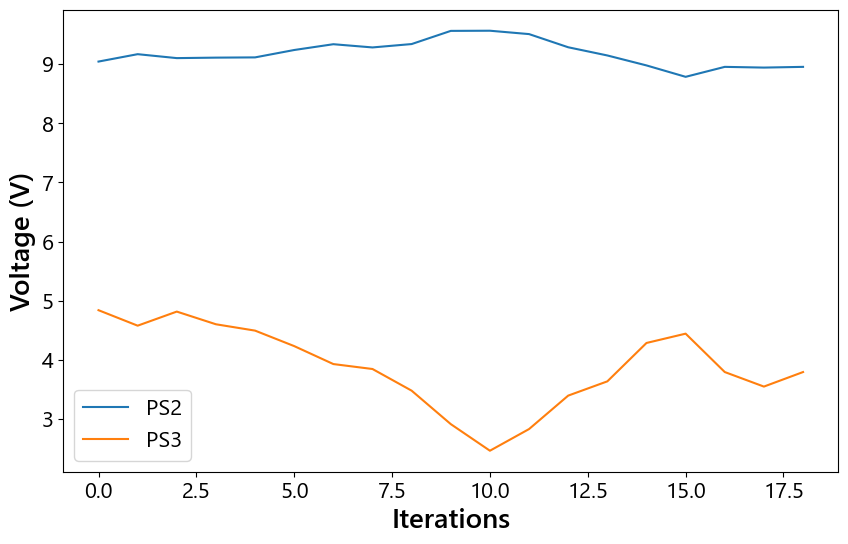

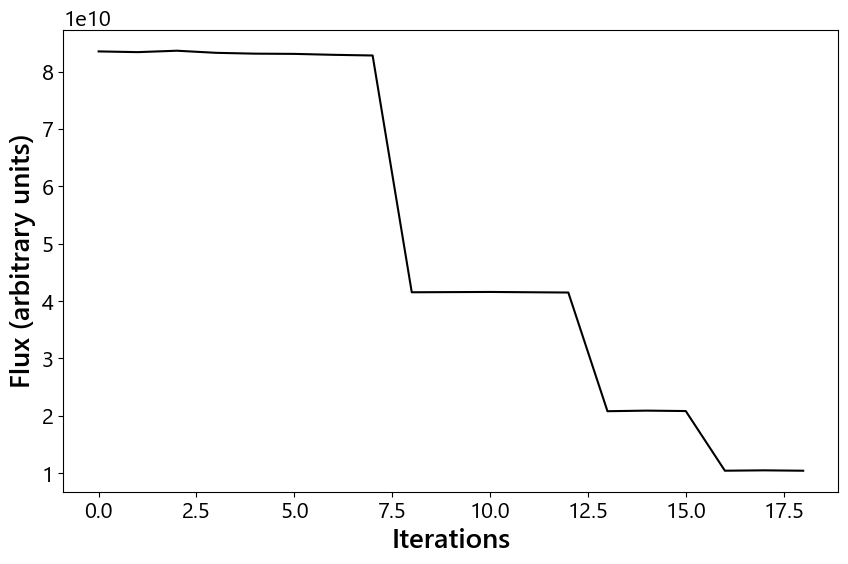

In [13]:
device_name = 'Device7a_I21_1x5Tri'
data_dir = f'D:\\Active_PIC\\Data\\PhotometryScans\\{device_name}\\20260821\\null_search\\'
exp_name = 'Ch68_V9p000_TECon_polarizer'

bench.apply_voltage(68, 9.1)

initial_voltages = np.array([9.0, 4.5])
channels = [('keysight', 3), ('keysight', 2)]
num_outputs, ind_null, inds_norm = 1, 0, None
bounds = [(0., 16.), (0., 16.)]

res, null_depth, all_voltages, null_metrics, temps = bench.optimize_null(
    initial_voltages, channels, bench.coords, ind_null,
    inds_norm=inds_norm, plot=False, r_max=20, r_lin=8,
    bounds=bounds, sig_v=0.2, xatol=0.001)

plt.figure(figsize=(10,6))
plt.plot(all_voltages[:,0], label='PS2')
plt.plot(all_voltages[:,1], label='PS3')
# plt.plot(all_voltages[:,2], label='PS3')
plt.xticks(fontsize=16)
plt.yticks(fontsize=16)
plt.xlabel('Iterations', fontsize=20)
plt.ylabel('Voltage (V)', fontsize=20)
plt.legend(fontsize=16)
plt.show()

plt.figure(figsize=(10,6))
# plt.plot(10*np.log10(null_metrics), 'k')
plt.plot(null_metrics, 'k')
plt.xticks(fontsize=16)
plt.yticks(fontsize=16)
plt.xlabel('Iterations', fontsize=20)
plt.ylabel('Flux (arbitrary units)', fontsize=20)
# plt.ylim(-60, 0)
plt.show()

os.makedirs(data_dir, exist_ok=True)
np.save(f"{data_dir}{device_name}_{exp_name}_voltages.npy", all_voltages)
np.save(f"{data_dir}{device_name}_{exp_name}_null.npy", null_metrics)
np.save(f"{data_dir}{device_name}_{exp_name}_temperature.npy", temps)

# 1D voltage scan

In [16]:
bench.apply_voltage(66, 12)

XDAC        : DEBUG    Sent XDAC command: "SETV:66:12.000".
XDAC        : DEBUG    XDAC answer = {12.000}
XDAC        : DEBUG    Channel 66 set to 12 V.


In [17]:
device_name = 'Device5a_I15_1x3Tri'

# # PS1 on the XDAC, PS2 and PS3 on the Keysight
# PS1 = 68
# PS2, PS3 = ('keysight', 3), ('keysight', 2)
PS3 = 66
# V_PS1 = 9.1
# bench.apply_voltage(PS1, V_PS1)
# PS1_str = f'{bench._channel_label(PS1)}_V{V_PS1:0.3f}'.replace('.', 'p')

# exp_name = f'{PS1_str}_TECon_polarizer_adaptive_trial0'
# filename_root = f'{data_dir}{device_name}_{PS1_str}'
exp_name = 'TECon_polarizer_adaptive_trial2'
data_dir = f'D:\\Active_PIC\\Data\\PhotometryScans\\{device_name}\\20260921\\voltage_scan\\{device_name}_{exp_name}\\'
filename_root = f'{data_dir}{device_name}'


os.makedirs(data_dir, exist_ok=True)


# channels_fix = [PS2]
# voltages_fix = [np.linspace(all_voltages[-1,0]-0.3, all_voltages[-1,0]+0.3, 31)]
channels_fix = []
voltages_fix = []
channel_adapt, adapt_lim, adapt_step = PS3, [0.0, 13.0], 0.1
output_coords = [coord.astype(int) for coord in bench.coords]
attens = [49.0]*len(output_coords)
ind_null = 0

dats = bench.voltage_scan_adaptive(channels_fix, voltages_fix, channel_adapt, adapt_lim, adapt_step, filename_root, output_coords, ind_null, attens)

XDAC        : DEBUG    Sent XDAC command: "SETV:66:0.000".
XDAC        : DEBUG    XDAC answer = {0.000}
XDAC        : DEBUG    Channel 66 set to 0.0 V.
XDAC        : DEBUG    Sent XDAC command: "MEASV:66".
XDAC        : DEBUG    XDAC answer = {3.93887}
XDAC        : DEBUG    Sent XDAC command: "MEASC:66".
XDAC        : DEBUG    XDAC answer = {0.00000}
TLX2        : DEBUG    VOA set to 20.0 dB.
XDAC        : DEBUG    Sent XDAC command: "SETV:60:4.080".
XDAC        : DEBUG    XDAC answer = {4.080}
XDAC        : DEBUG    Channel 60 set to 4.079666022597483 V.
TLX2        : DEBUG    VOA set to 20.0 dB.
XDAC        : DEBUG    Sent XDAC command: "SETV:60:4.195".
XDAC        : DEBUG    XDAC answer = {4.195}
XDAC        : DEBUG    Channel 60 set to 4.194764577122529 V.
TLX2        : DEBUG    VOA set to 20.0 dB.
XDAC        : DEBUG    Sent XDAC command: "SETV:60:4.301".
XDAC        : DEBUG    XDAC answer = {4.301}
XDAC        : DEBUG    Channel 60 set to 4.301479769580663 V.
TLX2        : DEBUG

KeyboardInterrupt: 

In [16]:
bench.close()

TLX2        : DEBUG    Laser set to off.
TLX2        : DEBUG    Laser set to off.
TLX2        : INFO     Connection to TLX2 laser closed.
TEC         : INFO     Temperature control loop off.
TEC         : INFO     Temperature control loop off.
Connection to Arduino closed.
Zaber       : INFO     Connection to Zabers closed.
XenicsCam   : INFO     Stopped streaming frames!
XenicsCam   : INFO     Camera closed!
XDAC        : DEBUG    Sent XDAC command: "ZERO:ALL".
XDAC        : DEBUG    XDAC answer = {OK}
XDAC        : DEBUG    Sent XDAC command: "SETMULTIA;;:C1:150.000:C2:150.000:C3:150.000:C4:150.000:C5:150.000:C6:150.000:C7:150.000:C8:150.000:C9:150.000:C10:150.000:C11:150.000:C12:150.000:C13:150.000:C14:150.000:C15:150.000:C16:150.000:C17:150.000:C18:150.000:C19:150.000:C20:150.000:C21:150.000:C22:150.000:C23:150.000:C24:150.000:C25:150.000:C26:150.000:C27:150.000:C28:150.000:C29:150.000:C30:150.000:C31:150.000:C32:150.000:C33:150.000:C34:150.000:C35:150.000:C36:150.000:C37:150.000:C

# Combine Nelder-Mead and voltage scan

XDAC        : DEBUG    Sent XDAC command: "SETV:61:9.000".
XDAC        : DEBUG    XDAC answer = {9.000}
XDAC        : DEBUG    Channel 61 set to 9.0 V.
(PS1 = 9.0 V) Nelder-Mead optimization...
XDAC        : DEBUG    Sent XDAC command: "SETV:62:10.112".
XDAC        : DEBUG    XDAC answer = {10.112}
XDAC        : DEBUG    Channel 62 set to 10.111964669581875 V.
XDAC        : DEBUG    Sent XDAC command: "SETV:41:1.348".
XDAC        : DEBUG    XDAC answer = {1.348}
XDAC        : DEBUG    Channel 41 set to 1.3479124533053584 V.
TLX2        : DEBUG    VOA set to 20.0 dB.
XDAC        : DEBUG    Sent XDAC command: "SETV:60:4.140".
XDAC        : DEBUG    XDAC answer = {4.140}
XDAC        : DEBUG    Channel 60 set to 4.1398304143354405 V.
Bench       : INFO     voltages:[10.11196467  1.34791245]
Bench       : INFO     Null mode intensities: [4.149429e+10]
Bench       : INFO     Side mode intensities: 1
Bench       : INFO     Null: [106.179886] dB
Bench       : INFO     

XDAC        : DEBUG    

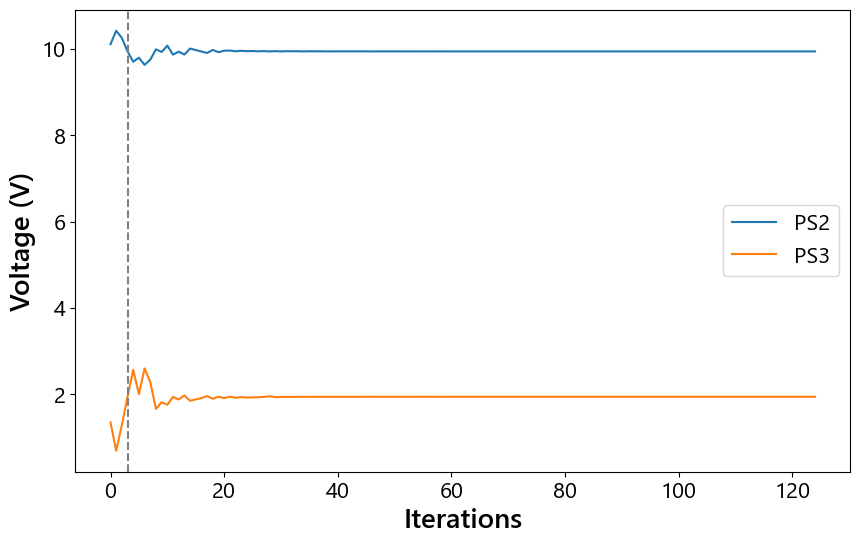

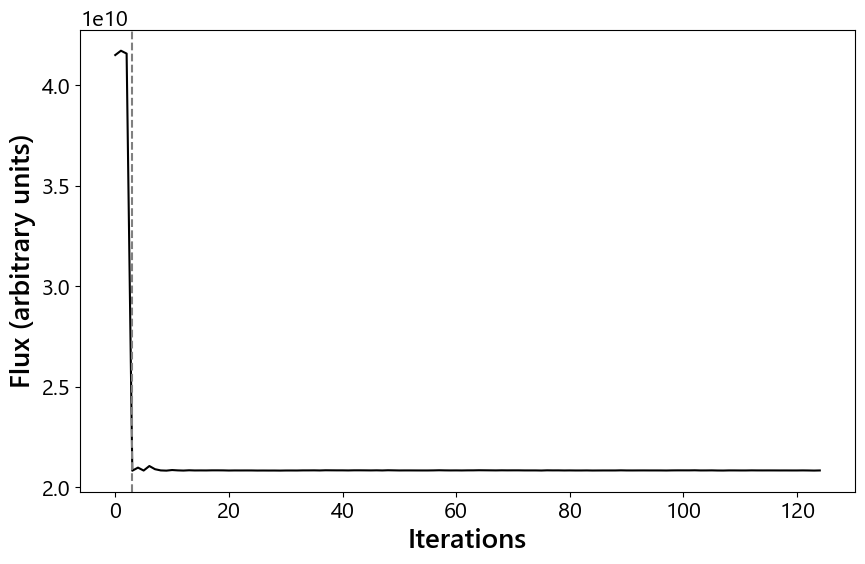

(PS1 = 9.0 V) Nelder-Mead optimization done.
(PS1 = 9.0 V) Voltage scan...
XDAC        : DEBUG    Sent XDAC command: "SETV:62:9.646".
XDAC        : DEBUG    XDAC answer = {9.646}
XDAC        : DEBUG    Channel 62 set to 9.645515727369432 V.
XDAC        : DEBUG    Sent XDAC command: "MEASV:62".
XDAC        : DEBUG    XDAC answer = {9.25215}
XDAC        : DEBUG    Sent XDAC command: "MEASC:62".
XDAC        : DEBUG    XDAC answer = {88.29763}
XDAC        : DEBUG    Sent XDAC command: "SETV:41:0.000".
XDAC        : DEBUG    XDAC answer = {0.000}
XDAC        : DEBUG    Channel 41 set to 0.0 V.
XDAC        : DEBUG    Sent XDAC command: "MEASV:41".
XDAC        : DEBUG    XDAC answer = {0.61191}
XDAC        : DEBUG    Sent XDAC command: "MEASC:41".
XDAC        : DEBUG    XDAC answer = {0.00000}
TLX2        : DEBUG    VOA set to 20.0 dB.
XDAC        : DEBUG    Sent XDAC command: "SETV:60:4.465".
XDAC        : DEBUG    XDAC answer = {4.465}
XDAC        : DEBUG    Channel 60 set to 4.464570852711

ValueError: Output A saturating at max attenuation limit of VOA.

In [4]:
device_name = 'Device6a_I18_1x5Tri'
PS1 = 61
PS2, PS3 = 62, 41
data_dir_root = f'D:\\Active_PIC\\Data\\PhotometryScans\\{device_name}\\20261027\\'

amoeba_channels = [PS2, PS3]
voltages_PS1 = np.arange(9.0, 11.1, 0.25)

for V_PS1 in voltages_PS1:

    bench.apply_voltage(PS1, V_PS1)
    amoeba_init = np.array([10, 0.5])

    # Nelder-Mead optimization
    print(f'(PS1 = {V_PS1} V) Nelder-Mead optimization...')
    PS1_str = f'{bench.channel_label(PS1)}_V{V_PS1:0.3f}'.replace('.', 'p')
    exp_name = f'{PS1_str}_TECon_polarizer'
    data_dir = f'{data_dir_root}voltage_scan_{exp_name}\\null_scan\\'
    os.makedirs(data_dir, exist_ok=True)
    
    num_outputs, ind_null, inds_norm = 1, 0, None
    bounds = [(0., 12), (0., 12)]

    res, null_depth, all_voltages, null_metrics, temps = bench.optimize_null(
        amoeba_init, amoeba_channels, bench.coords, ind_null,
        inds_norm=inds_norm, plot=False, r_max=20, r_lin=8,
        bounds=bounds, sig_v=0.5, xatol=0.01, max_iter=50)

    while null_metrics[-1] > null_metrics[0]:
        res, null_depth, all_voltages, null_metrics, temps = bench.optimize_null(
                amoeba_init, amoeba_channels, bench.coords, ind_null,
                inds_norm=inds_norm, plot=False, r_max=20, r_lin=8,
                bounds=bounds, sig_v=1.0, xatol=0.01, max_iter=50)
    #     raise ValueError(f'Nelder-Mead did not converge to an optimized solution: {all_voltages[-1]}')

    i_best = np.argmin(null_metrics)
    best_voltages, null_depth = all_voltages[i_best], null_metrics[i_best]
    
    print(res.message, res.nit, res.nfev)
    
    plt.figure(figsize=(10,6))
    plt.plot(all_voltages[:,0], label='PS2')
    plt.plot(all_voltages[:,1], label='PS3')
    plt.axvline(i_best, color='grey', linestyle='dashed')
    # plt.plot(all_voltages[:,2], label='PS3')
    plt.xticks(fontsize=16)
    plt.yticks(fontsize=16)
    plt.xlabel('Iterations', fontsize=20)
    plt.ylabel('Voltage (V)', fontsize=20)
    plt.legend(fontsize=16)
    plt.savefig(f'{data_dir}null_scan_voltages_{exp_name}.png', dpi=300, bbox_inches='tight', transparent=True)
    plt.show()

    plt.figure(figsize=(10,6))
    # plt.plot(10*np.log10(null_metrics), 'k')
    plt.plot(null_metrics, 'k')
    plt.axvline(i_best, color='grey', linestyle='dashed')
    plt.xticks(fontsize=16)
    plt.yticks(fontsize=16)
    plt.xlabel('Iterations', fontsize=20)
    plt.ylabel('Flux (arbitrary units)', fontsize=20)
    plt.savefig(f'{data_dir}null_scan_nullMetric_{exp_name}.png', dpi=300, bbox_inches='tight', transparent=True)
    # plt.ylim(-60, 0)
    plt.show()

    os.makedirs(data_dir, exist_ok=True)
    np.save(f"{data_dir}{device_name}_{exp_name}_voltages.npy", all_voltages)
    np.save(f"{data_dir}{device_name}_{exp_name}_null.npy", null_metrics)
    np.save(f"{data_dir}{device_name}_{exp_name}_temperature.npy", temps)
    print(f'(PS1 = {V_PS1} V) Nelder-Mead optimization done.')

    # Voltage scan
    print(f'(PS1 = {V_PS1} V) Voltage scan...')
    data_dir = f'{data_dir_root}voltage_scan_{exp_name}\\voltage_scan\\'
    os.makedirs(data_dir, exist_ok=True)
    filename_root = f'{data_dir}{device_name}_{PS1_str}'

    channels_fix = [PS2]
    voltages_fix = [np.linspace(best_voltages[0]-0.3, best_voltages[0]+0.3, 11)]
    channel_adapt, adapt_lim, adapt_step = PS3, [0.0, 12.0], 0.1
    output_coords = [coord.astype(int) for coord in bench.coords]
    attens = [49.0]*len(output_coords)
    ind_null = 0

    dats = bench.voltage_scan_adaptive(channels_fix, voltages_fix, channel_adapt, adapt_lim, adapt_step, filename_root, output_coords, ind_null, attens)
    print(f'(PS1 = {V_PS1} V) Voltage scan done.')

In [5]:
bench.close()

TLX2        : DEBUG    Laser set to off.
TLX2        : DEBUG    Laser tuned to channel 45, 1589.9892 nm.
TLX2        : DEBUG    Fine tuning offset set to 0 MHz, now at 1589.9892 nm.
TLX2        : DEBUG    Laser set to off.
TLX2        : INFO     Connection to TLX2 laser closed.
TEC         : INFO     Temperature control loop off.
TEC         : INFO     Temperature control loop off.
Connection to Arduino closed.
Zaber       : INFO     Connection to Zabers closed.
XenicsCam   : INFO     Stopped streaming frames!
XenicsCam   : INFO     Camera closed!
XDAC        : DEBUG    Sent XDAC command: "ZERO:ALL".
XDAC        : DEBUG    XDAC answer = {OK}
XDAC        : DEBUG    Sent XDAC command: "SETMULTIA;;:C1:150.000:C2:150.000:C3:150.000:C4:150.000:C5:150.000:C6:150.000:C7:150.000:C8:150.000:C9:150.000:C10:150.000:C11:150.000:C12:150.000:C13:150.000:C14:150.000:C15:150.000:C16:150.000:C17:150.000:C18:150.000:C19:150.000:C20:150.000:C21:150.000:C22:150.000:C23:150.000:C24:150.000:C25:150.000:C26:

# 1D laser scan

In [12]:
from Bench import CAM_NAVG

def laser_scan(self, channels, channel_ps, wav_ref, wavs, filename_root,
               coords, attens, ind_null, initial_voltages,
               min_range=0.2, min_step=0.001,
               max_low=10.0, max_up=13.0, max_step=0.2,
               navg=CAM_NAVG, optimize=True, **optimize_kwargs):
        ''' Measures null degradation and null phase shifter voltage against wavelength.

            The null is found at the reference wavelength with optimize_null. The
            other channels are then held at those settings for every wavelength, and
            only channel_ps is swept, so a change in null depth reflects wavelength
            rather than re-tuning.

            At each wavelength the phase shifter is swept over two windows:

                minimum   v_ref - min_range to v_ref + min_range, in min_step,
                        where v_ref is the null voltage found at wav_ref.
                        Resolves the null itself and the voltage it sits at.
                maximum   max_low to max_up, in max_step, as absolute voltages.
                        Supplies the maximum the null is normalised against.
                        Set these to bracket the fringe peak, which sits about a
                        quarter of a fringe from the null.

            Images and log rows are saved for every point; the null depth and the
            null voltage come out of the reduction rather than being computed here,
            so they use the same photometry as the rest of the analysis.

            The two windows are disjoint in phase shifter voltage, so a reduction
            can take the null as the minimum and the normalisation as the maximum
            over all points at a wavelength without needing to know which window
            each point came from.

            Filenames carry the requested wavelength rather than the achieved one,
            since the laser tunes on a 50 GHz grid. Both go in the log.

            Parameters
            ----------
            channels : n x 1 numpy array of integers
                TOPM channels held fixed at their reference-wavelength settings
            channel_ps : integer
                Phase shifter channel swept at every wavelength
            wav_ref : float
                Reference wavelength (nm) at which the null is found
            wavs : List of float
                Wavelengths (nm) to measure the null at. wav_ref is measured first
                whether or not it appears here.
            filename_root : string
                Path and prefix for each file produced by this routine
            coords : Nx2 numpy array or list of integers
                Approximate coordinates of output port pixels
            attens : 1xN numpy array
                Initial attenuations for each of the outputs
            ind_null : integer
                Index of the null port in coords
            initial_voltages : 1D numpy array
                Starting voltages for channels then channel_ps
            min_range : float
                Half-width in V of the minimum window around v_ref. Default: 0.2
            min_step : float
                Step in V within the minimum window. Default: 0.001
            max_low, max_up : float
                Absolute voltages bounding the maximum window. Default: 10.0 and 13.0
            max_step : float
                Step in V within the maximum window. Default: 0.2
            navg : int
                Number of camera frames to average together when collecting data
            optimize : boolean
                Whether to run optimize_null at wav_ref. If False, initial_voltages
                is used as the null setting directly.
            optimize_kwargs : dict
                Further keyword arguments for optimize_null

            Returns
            -------
            dats : 2D numpy array
                Table of data log containing XCOM device and laser readout settings
        '''

        import logging
        _log = logging.getLogger('Bench')
        
        channels = list(channels)
        all_channels = channels + [channel_ps]
        initial_voltages = np.asarray(initial_voltages, dtype=float)

        if len(initial_voltages) != len(all_channels):
            raise ValueError(
                f'initial_voltages needs {len(all_channels)} entries, one per channel '
                f'in {channels} plus the phase shifter {channel_ps}. '
                f'Got {len(initial_voltages)}.')

        if max_low >= max_up:
            raise ValueError(f'max_low {max_low} must be below max_up {max_up}.')

        dats = []

        # --- find the null at the reference wavelength ---
        if optimize:
            wav_ref_true = self.tlx.laser_tune(wav_ref)
            _log.info(f'Optimizing null at {wav_ref} nm (reached {wav_ref_true:.4f} nm)...')

            res, null_depth, all_voltages, null_metrics, temps = self.optimize_null(initial_voltages, 
                                                                                        all_channels, coords, ind_null, **optimize_kwargs)
            while null_metrics[-1] > null_metrics[0]:
                res, null_depth, all_voltages, null_metrics, temps = self.optimize_null(initial_voltages, 
                                                                                        all_channels, coords, ind_null, **optimize_kwargs)
            null_voltages = np.asarray(res.x, dtype=float)
            i_best = np.argmin(null_metrics)
            
            print(res.message, res.nit, res.nfev)
            
            plt.figure(figsize=(10,6))
            for i in range(len(all_channels)):
                plt.plot(all_voltages[:,i])
            plt.axvline(i_best, color='grey', linestyle='dashed')
            plt.xticks(fontsize=16)
            plt.yticks(fontsize=16)
            plt.xlabel('Iterations', fontsize=20)
            plt.ylabel('Voltage (V)', fontsize=20)
            # plt.legend(fontsize=16)
            plt.show()
        
            plt.figure(figsize=(10,6))
            plt.plot(null_metrics, 'k')
            plt.axvline(i_best, color='grey', linestyle='dashed')
            plt.xticks(fontsize=16)
            plt.yticks(fontsize=16)
            plt.xlabel('Iterations', fontsize=20)
            plt.ylabel('Flux (arbitrary units)', fontsize=20)
            plt.show()
        else:
            null_voltages = initial_voltages

        # channels only: the phase shifter is the last entry and gets swept, so it
        # must not be included in the settings held fixed.
        topm_voltages = null_voltages[:len(channels)]
        v_ref = float(null_voltages[-1])
        _log.info(f'Reference null: {channels} at {topm_voltages}, '
                f'{channel_ps} at {v_ref:.3f} V')

        # --- phase shifter windows ---
        ceiling = self.channel_maxvoltage(channel_ps)

        ps_min = np.arange(v_ref - min_range, v_ref + min_range + 0.5*min_step, min_step)
        ps_max = np.arange(max_low, max_up + 0.5*max_step, max_step)

        ps_min = ps_min[(ps_min >= 0.0) & (ps_min <= ceiling)]
        ps_max = ps_max[(ps_max >= 0.0) & (ps_max <= ceiling)]

        if len(ps_min) == 0 or len(ps_max) == 0:
            raise ValueError(
                f'A phase shifter window lies outside 0-{ceiling} V for channel '
                f'{channel_ps} with v_ref {v_ref:.3f} V.')

        _log.info(f'Minimum window: {ps_min[0]:.3f} to {ps_min[-1]:.3f} V, {len(ps_min)} points')
        _log.info(f'Maximum window: {ps_max[0]:.3f} to {ps_max[-1]:.3f} V, {len(ps_max)} points')

        # Voltage grid for the ceiling checks and the crop
        voltages_for_setup = [[v] for v in topm_voltages]
        voltages_for_setup.append(np.concatenate([ps_min, ps_max]))
        _, crop = self._scan_setup(all_channels, voltages_for_setup, coords, filename_root)

        # wav_ref first, then the rest, without measuring it twice
        wav_list = [wav_ref] + [w for w in wavs if not np.isclose(w, wav_ref)]

        for wav in wav_list:
            wav_true = self.tlx.laser_tune(wav)
            wav_str = "{:.3f}".format(round(wav, 3)).replace('.', 'p')
            _log.info(f'--- {wav} nm (reached {wav_true:.4f} nm) ---')

            # TOPMs back to the reference setting: the previous wavelength left the
            # phase shifter elsewhere, and re-applying guards against drift in the
            # tracked state.
            table_row_fix, channel_str_fix = self._set_channels(
                channels, topm_voltages, channel_str=f'_wav{wav_str}')

            for v_ps in np.concatenate([ps_min, ps_max]):
                table_row, channel_str = self._set_channels(
                    [channel_ps], [v_ps], table_row=table_row_fix,
                    channel_str=channel_str_fix)
                self._measure_and_save(coords, attens, filename_root, channel_str,
                                    table_row, crop, dats, navg=navg,
                                    extra=[wav, wav_true])

        channel_str, header_str = self._scan_header(
            all_channels, extra_cols=('laserWavRequested', 'laserWav'))
        np.savetxt(filename_root + channel_str + '.log', dats,
                header=header_str, delimiter=",")

        return np.array(dats)     

In [13]:
bench.tec.read_temperature()

17.995

In [14]:
device_name = 'Device5a_I15_1x3Tri'

# PS1, V_PS1 = 61, 10.0
# bench.apply_voltage(PS1, V_PS1)
# PS1_str = f'{bench.channel_label(PS1)}_V{V_PS1:0.3f}'.replace('.', 'p')
# exp_name = f'{PS1_str}_TECon_polarizer_adaptive_trial0'
exp_name = f'TECon_polarizer_adaptive_trial0'

data_dir = f'D:\\Active_PIC\\Data\\PhotometryScans\\{device_name}\\20260922\\laser_scan\\{device_name}_{exp_name}\\'
os.makedirs(data_dir, exist_ok=True)
filename_root = f'{data_dir}{device_name}'

# PS2, PS3 = 62, 41
# channels = [PS2]
PS3 = 66
channel_ps = PS3
channels = []

wav_ref, wavs = 1590., np.arange(1575, 1606, 3)
output_coords = [coord.astype(int) for coord in bench.coords]
attens = [49.0]*len(output_coords)
ind_null = 0

initial_voltages = np.array([12.5])

num_outputs, ind_null, inds_norm = 1, 0, None
# bounds = [(0., 12.), (0., 12.)]
bounds = [(0., 13.)]

# try:
dats = laser_scan(bench, channels, channel_ps, wav_ref, wavs, filename_root, 
                    output_coords, attens, ind_null,
                    initial_voltages, min_step=0.002, min_range=0.4, max_low=6, max_up=10, optimize=True, inds_norm=inds_norm, 
                    plot=False, r_max=20, r_lin=8, bounds=bounds, sig_v=0.5, xatol=0.01, max_iter=50) 
# except BaseException:
#     try:
#         bench.close()
#     except Exception as e:
#         print(f'close() also failed: {type(e).__name__}: {e}')
#     raise

TLX2        : DEBUG    Fine tuning offset set to -1284 MHz, now at 1590.0000 nm.
TLX2        : DEBUG    Requested 1590.0 nm, reached 1589.99998 nm on channel 45 with -1284 MHz offset.
Bench       : INFO     Optimizing null at 1590.0 nm (reached 1590.0000 nm)...
XDAC        : DEBUG    Sent XDAC command: "SETV:66:12.612".
XDAC        : DEBUG    XDAC answer = {12.612}
XDAC        : DEBUG    Channel 66 set to 12.611964669581875 V.
TLX2        : DEBUG    VOA set to 20.0 dB.
XDAC        : DEBUG    Sent XDAC command: "SETV:60:3.674".
XDAC        : DEBUG    XDAC answer = {3.674}
XDAC        : DEBUG    Channel 60 set to 3.673824949138076 V.
TLX2        : DEBUG    VOA set to 20.0 dB.
XDAC        : DEBUG    Sent XDAC command: "SETV:60:3.821".
XDAC        : DEBUG    XDAC answer = {3.821}
XDAC        : DEBUG    Channel 60 set to 3.8209618735321103 V.
TLX2        : DEBUG    VOA set to 20.0 dB.
XDAC        : DEBUG    Sent XDAC command: "SETV:60:3.956".
XDAC        : DEBUG    XDAC answer = {3.956}
XDA

KeyboardInterrupt: 

In [ ]:
bench.close()

TLX2        : DEBUG    Laser set to off.
TLX2        : DEBUG    Laser tuned to channel 45, 1590.1023 nm.
TLX2        : DEBUG    Fine tuning offset set to 0 MHz, now at 1589.9892 nm.
TLX2        : DEBUG    Laser set to off.
TLX2        : INFO     Connection to TLX2 laser closed.
TEC         : INFO     Temperature control loop off.
TEC         : INFO     Temperature control loop off.
Connection to Arduino closed.
Zaber       : INFO     Connection to Zabers closed.
XenicsCam   : INFO     Stopped streaming frames!
XenicsCam   : INFO     Camera closed!
XDAC        : DEBUG    Sent XDAC command: "ZERO:ALL".
XDAC        : DEBUG    XDAC answer = {OK}
XDAC        : DEBUG    Sent XDAC command: "SETMULTIA;;:C1:150.000:C2:150.000:C3:150.000:C4:150.000:C5:150.000:C6:150.000:C7:150.000:C8:150.000:C9:150.000:C10:150.000:C11:150.000:C12:150.000:C13:150.000:C14:150.000:C15:150.000:C16:150.000:C17:150.000:C18:150.000:C19:150.000:C20:150.000:C21:150.000:C22:150.000:C23:150.000:C24:150.000:C25:150.000:C26:

# Null stability over time

In [ ]:
from Bench import CAM_NAVG
import glob
import time
import logging
_log = logging.getLogger('Bench')
sys.path.append('D://Active_PIC//AnalysisCode//')
import PIC_lib as PIC


def null_stability_track(self, t_int, channels, channel_ps, filename_root,
                         coords, attens, ind_null, initial_voltages,
                         min_range=0.2, min_step=0.001,
                         max_low=10.0, max_up=13.0, max_step=0.2,
                         track_cadence=0.0, optimize_attempts=3,
                         navg=CAM_NAVG, optimize=True, **optimize_kwargs):
    ''' Finds a null, confirms it with a fine sweep, then holds it and tracks its
        stability over time.

        Runs in three phases:

          1. optimize_null over channels and channel_ps, from initial_voltages.
             Retried up to optimize_attempts times if it ends worse than it
             started.
          2. A confirmation sweep of channel_ps over two windows, with the other
             channels held at their optimised settings:

               minimum   v_ref - min_range to v_ref + min_range, in min_step,
                         where v_ref is the optimiser's phase shifter voltage.
                         Resolves the null and the voltage it sits at.
               maximum   max_low to max_up, in max_step, as absolute voltages.
                         Supplies the maximum the null is normalised against.
                         Set these to bracket the fringe peak, about a quarter
                         of a fringe from the null.

             The sweep is reduced immediately to locate the null voltage, which
             is more reliable than the optimiser's own last point: the metric is
             noisy, so the optimiser can stop somewhere slightly off the true
             minimum.
          3. All channels held at the null, taking an image every track_cadence
             seconds for t_int seconds.

        The two windows are disjoint in phase shifter voltage, so the reduction
        can take the null as the minimum and the normalisation as the maximum
        over all sweep points without needing to know which window each came
        from.

        Two logs are written: '<root>_sweep.log' for phase 2 and
        '<root>_track.log' for phase 3. Tracking filenames carry a '_tNNNNN'
        index, since the voltages no longer change and would otherwise produce
        the same filename every time.

        Parameters
        ----------
        t_int : float
            Duration in seconds of the tracking phase
        channels : n x 1 numpy array of integers
            Channels held fixed at their optimised settings during the sweep
        channel_ps : integer
            Phase shifter channel swept to confirm the null
        filename_root : string
            Path and prefix for each file produced by this routine
        coords : Nx2 numpy array or list of integers
            Approximate coordinates of output port pixels
        attens : 1xN numpy array
            Initial attenuations for each of the outputs
        ind_null : integer
            Index of the null port in coords
        initial_voltages : 1D numpy array
            Starting voltages for channels then channel_ps
        min_range : float
            Half-width in V of the minimum window around v_ref. Default: 0.2
        min_step : float
            Step in V within the minimum window. Default: 0.001
        max_low, max_up : float
            Absolute voltages bounding the maximum window. Default: 10.0 and 13.0
        max_step : float
            Step in V within the maximum window. Default: 0.2
        track_cadence : float
            Target seconds between tracking measurements. 0 means as fast as the
            camera allows. If a measurement takes longer than this, the cadence
            is set by the measurement. Default: 0.0
        optimize_attempts : int
            How many times to retry optimize_null if it ends worse than it
            started. Default: 3
        navg : int
            Number of camera frames to average together when collecting data
        optimize : boolean
            Whether to run optimize_null. If False, initial_voltages is used as
            the null setting directly and phase 1 is skipped.
        optimize_kwargs : dict
            Further keyword arguments for optimize_null

        Returns
        -------
        dats_sweep : 2D numpy array
            Log rows from the confirmation sweep
        dats_track : 2D numpy array
            Log rows from the tracking phase
        opt : dict
            Optimiser diagnostics: 'all_voltages', 'null_metrics', 'temps',
            'i_best', 'message', 'nit', 'nfev', and the located 'v_null'.
            Empty if optimize is False. Returned rather than plotted so the
            tracking phase is not held up waiting for a figure to be closed.
    '''
    channels = list(channels)
    all_channels = channels + [channel_ps]
    initial_voltages = np.asarray(initial_voltages, dtype=float)

    if len(initial_voltages) != len(all_channels):
        raise ValueError(
            f'initial_voltages needs {len(all_channels)} entries, one per channel '
            f'in {channels} plus the phase shifter {channel_ps}. '
            f'Got {len(initial_voltages)}.')

    if max_low >= max_up:
        raise ValueError(f'max_low {max_low} must be below max_up {max_up}.')

    dats_sweep = []
    dats_track = []
    opt = {}

    # --- phase 1: find the null ---
    if optimize:
        _log.info(f'Optimizing null over {all_channels} from {initial_voltages}...')

        for attempt in range(optimize_attempts):
            res, null_depth, all_voltages, null_metrics, temps = self.optimize_null(
                initial_voltages, all_channels, coords, ind_null, **optimize_kwargs)

            if null_metrics[-1] <= null_metrics[0]:
                break

            # A bounded retry, not a while loop: optimize_null seeds its random
            # simplex with a fixed seed, so an unbounded retry from the same
            # starting point would repeat the same result forever.
            _log.warning(f'Optimization attempt {attempt + 1} of {optimize_attempts} '
                         f'ended worse than it started.')

        null_metrics = np.asarray(null_metrics)
        i_best = int(np.nanargmin(null_metrics))

        # The optimiser's stopping point is not always its best point, since the
        # metric is noisy: take the best measured vertex instead.
        null_voltages = np.asarray(all_voltages, dtype=float)[i_best]

        opt = {'all_voltages': np.asarray(all_voltages), 'null_metrics': null_metrics,
               'temps': np.asarray(temps), 'i_best': i_best,
               'message': res.message, 'nit': res.nit, 'nfev': res.nfev}

        _log.info(f'Optimizer: {res.message} ({res.nit} iterations, {res.nfev} evaluations)')

        plt.figure(figsize=(10,6))
        plt.plot(all_voltages[:,0], label='PS2')
        plt.plot(all_voltages[:,1], label='PS3')
        plt.axvline(i_best, color='grey', linestyle='dashed')
        plt.xticks(fontsize=16)
        plt.yticks(fontsize=16)
        plt.xlabel('Iterations', fontsize=20)
        plt.ylabel('Voltage (V)', fontsize=20)
        plt.legend(fontsize=16)
        plt.show()
    
        plt.figure(figsize=(10,6))
        plt.plot(null_metrics, 'k')
        plt.axvline(i_best, color='grey', linestyle='dashed')
        plt.xticks(fontsize=16)
        plt.yticks(fontsize=16)
        plt.xlabel('Iterations', fontsize=20)
        plt.ylabel('Flux (arbitrary units)', fontsize=20)
        plt.show()
    else:
        null_voltages = initial_voltages

    # channels only: the phase shifter is the last entry and gets swept, so it
    # must not be included in the settings held fixed.
    topm_voltages = null_voltages[:len(channels)]
    v_ref = float(null_voltages[-1])
    _log.info(f'Nelder-Mead null: {channels} at {topm_voltages}, '
              f'{channel_ps} at {v_ref:.3f} V')

    # --- phase shifter windows ---
    ceiling = self.channel_maxvoltage(channel_ps)

    ps_min = np.arange(v_ref - min_range, v_ref + min_range + 0.5*min_step, min_step)
    ps_max = np.arange(max_low, max_up + 0.5*max_step, max_step)

    ps_min = ps_min[(ps_min >= 0.0) & (ps_min <= ceiling)]
    ps_max = ps_max[(ps_max >= 0.0) & (ps_max <= ceiling)]

    if len(ps_min) == 0 or len(ps_max) == 0:
        raise ValueError(
            f'A phase shifter window lies outside 0-{ceiling} V for channel '
            f'{channel_ps} with v_ref {v_ref:.3f} V.')

    _log.info(f'Minimum window: {ps_min[0]:.3f} to {ps_min[-1]:.3f} V, {len(ps_min)} points')
    _log.info(f'Maximum window: {ps_max[0]:.3f} to {ps_max[-1]:.3f} V, {len(ps_max)} points')

    # Voltage grid for the ceiling checks and the crop
    voltages_for_setup = [[v] for v in topm_voltages]
    voltages_for_setup.append(np.concatenate([ps_min, ps_max]))
    _, crop = self._scan_setup(all_channels, voltages_for_setup, coords, filename_root)

    # --- phase 2: confirmation sweep ---
    table_row_fix, channel_str_fix = self._set_channels(channels, topm_voltages)

    for v_ps in np.concatenate([ps_min, ps_max]):
        table_row, channel_str = self._set_channels(
            [channel_ps], [v_ps], table_row=table_row_fix,
            channel_str=channel_str_fix)
        self._measure_and_save(coords, attens, filename_root, channel_str,
                               table_row, crop, dats_sweep, navg=navg)

    channel_str, header_str = self._scan_header(all_channels)
    sweep_log = filename_root + channel_str + '_sweep.log'
    np.savetxt(sweep_log, dats_sweep, header=header_str, delimiter=",")

    # --- locate the null from the sweep ---
    # Reduced here rather than trusting the optimiser's last point, and using
    # the same photometry the rest of the analysis uses.
    filename_dark = glob.glob(filename_root + '*dark*')[0]
    voltages_red, outputs, attens_red, _, _ = PIC.reduce_voltage_scan(
        filename_root, len(coords), filename_dark, coords=coords,
        r_lin=5, r_max=15, plot=False)
    np.save(f'{filename_root}_voltage_sweep', voltages_red)
    np.save(f'{filename_root}_outputs_sweep', outputs)
    np.save(f'{filename_root}_attenuation_sweep', attens_red)

    flux = outputs[:, ind_null] * 10**(attens_red[:, ind_null] / 10)
    j = int(np.nanargmin(flux))
    v_null = float(voltages_red[j, -1])         # channel_ps is the last column
    opt['v_null'] = v_null

    _log.info(f'Sweep null at {channel_ps} = {v_null:.4f} V '
              f'({v_null - v_ref:+.4f} V from the optimiser), flux {flux[j]:.4g}')

    # --- phase 3: hold the null and track ---
    table_row_fix, channel_str_fix = self._set_channels(
        all_channels, np.append(topm_voltages, v_null))

    _log.info(f'Tracking for {t_int} s at {track_cadence} s cadence...')

    i = 0
    t0 = time.time()
    next_t = t0

    while time.time() <= t0 + t_int:
        # Index in the filename: the voltages no longer change, so without it
        # every measurement would overwrite the previous one.
        self._measure_and_save(coords, attens, filename_root,
                               channel_str_fix + f'_t{i:05d}',
                               table_row_fix, crop, dats_track, navg=navg)
        i += 1

        # Cadence measured from a running target rather than sleeping a fixed
        # time after each measurement, so the interval does not drift with the
        # measurement duration.
        next_t += track_cadence
        time.sleep(max(0.0, next_t - time.time()))

    track_log = filename_root + channel_str + '_track.log'
    np.savetxt(track_log, dats_track, header=header_str, delimiter=",")

    _log.info(f'Tracked {i} points over {time.time() - t0:.1f} s.')

    return np.array(dats_sweep), np.array(dats_track), opt

In [82]:
bench.tec.read_temperature()

17.995

XDAC        : DEBUG    Sent XDAC command: "SETV:61:10.000".
XDAC        : DEBUG    XDAC answer = {10.000}
XDAC        : DEBUG    Channel 61 set to 10.0 V.
Bench       : INFO     Optimizing null over [62, 41] from [8.5 0.5]...
XDAC        : DEBUG    Sent XDAC command: "SETV:62:8.545".
XDAC        : DEBUG    XDAC answer = {8.545}
XDAC        : DEBUG    Channel 62 set to 8.544785867832749 V.
XDAC        : DEBUG    Sent XDAC command: "SETV:41:0.839".
XDAC        : DEBUG    XDAC answer = {0.839}
XDAC        : DEBUG    Channel 41 set to 0.8391649813221433 V.
TLX2        : DEBUG    VOA set to 20.0 dB.
XDAC        : DEBUG    Sent XDAC command: "SETV:60:3.674".
XDAC        : DEBUG    XDAC answer = {3.674}
XDAC        : DEBUG    Channel 60 set to 3.673824949138076 V.
TLX2        : DEBUG    VOA set to 20.0 dB.
XDAC        : DEBUG    Sent XDAC command: "SETV:60:3.821".
XDAC        : DEBUG    XDAC answer = {3.821}
XDAC        : DEBUG    Channel 60 set to 3.8209618735321103 V.
TLX2        : DEBUG   

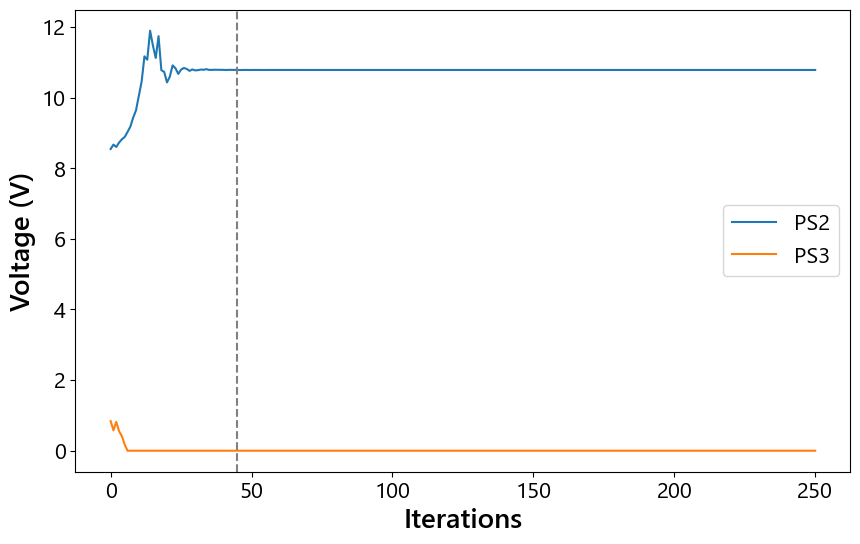

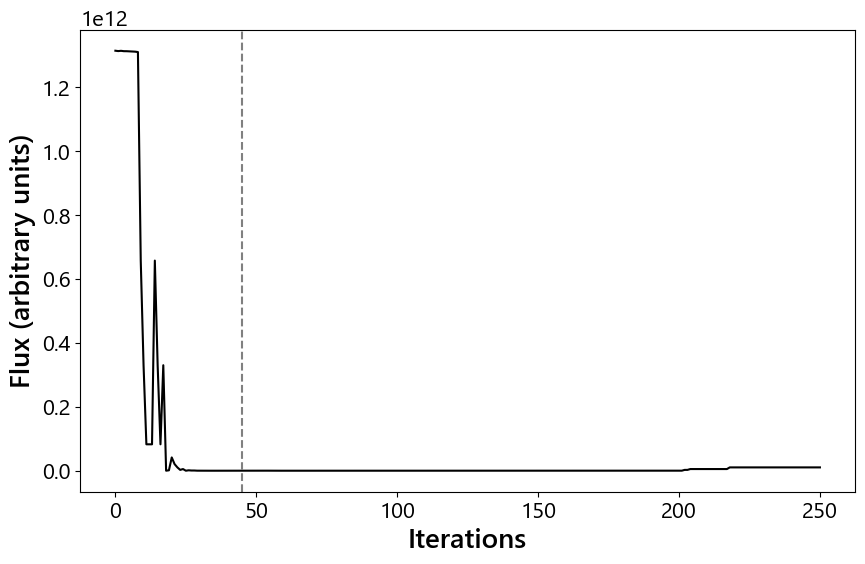

Bench       : INFO     Nelder-Mead null: [62] at [10.78329369], 41 at 0.000 V
Bench       : INFO     Minimum window: 0.000 to 0.200 V, 101 points
Bench       : INFO     Maximum window: 10.000 to 12.000 V, 11 points
XDAC        : DEBUG    Sent XDAC command: "SETV:62:10.783".
XDAC        : DEBUG    XDAC answer = {10.783}
XDAC        : DEBUG    Channel 62 set to 10.78329368700318 V.
XDAC        : DEBUG    Sent XDAC command: "MEASV:62".
XDAC        : DEBUG    XDAC answer = {10.35156}
XDAC        : DEBUG    Sent XDAC command: "MEASC:62".
XDAC        : DEBUG    XDAC answer = {96.51659}
XDAC        : DEBUG    Sent XDAC command: "SETV:41:0.000".
XDAC        : DEBUG    XDAC answer = {0.000}
XDAC        : DEBUG    Channel 41 set to 1.6653345369377348e-16 V.
XDAC        : DEBUG    Sent XDAC command: "MEASV:41".
XDAC        : DEBUG    XDAC answer = {0.23594}
XDAC        : DEBUG    Sent XDAC command: "MEASC:41".
XDAC        : DEBUG    XDAC answer = {0.00000}
TLX2        : DEBUG    VOA set to 20.0 d

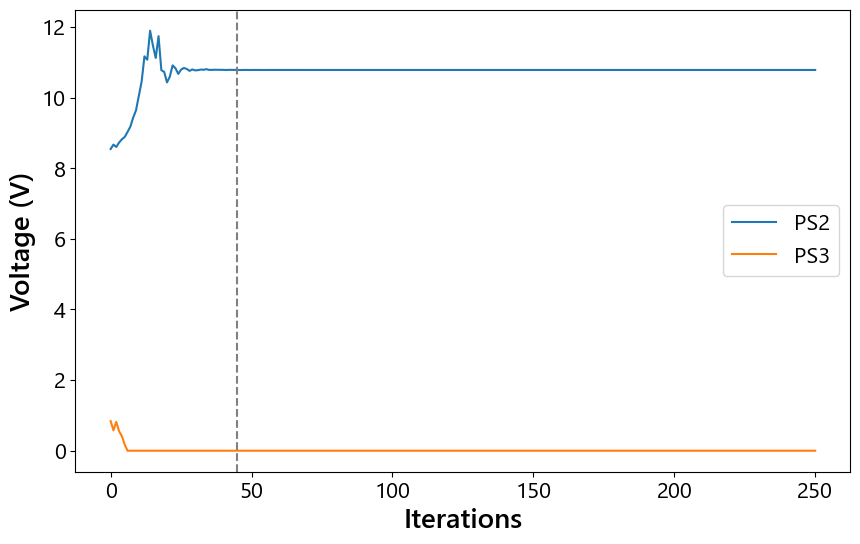

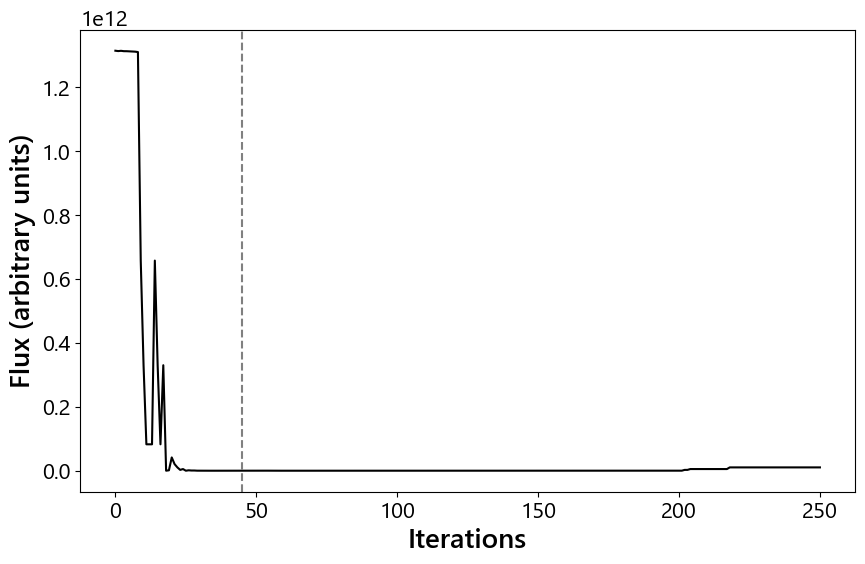

In [83]:
device_name = 'Device6a_I18_1x5Tri'

PS1, V_PS1 = 61, 10.0
bench.apply_voltage(PS1, V_PS1)
PS1_str = f'{bench.channel_label(PS1)}_V{V_PS1:0.3f}'.replace('.', 'p')

exp_name = f'{PS1_str}_TECon_polarizer_nulltrack_trial0'
data_dir = f'D:\\Active_PIC\\Data\\PhotometryScans\\{device_name}\\20260920\\null_track\\{device_name}_{exp_name}\\'
os.makedirs(data_dir, exist_ok=True)
filename_root = f'{data_dir}{device_name}_{PS1_str}'

# PS2, PS3 = ('keysight', 3), ('keysight', 2)
PS2, PS3 = 62, 41
channels = [PS2]
channel_ps = PS3

output_coords = [coord.astype(int) for coord in bench.coords]
attens = [49.0]*len(output_coords)
ind_null = 0

initial_voltages = np.array([8.5, 0.5])
bounds = [(0., 12.), (0., 12.)]

T_INT = 3600.0          # seconds of tracking
TRACK_CADENCE = 5.0     # seconds between tracking measurements

# try:
dats_sweep, dats_track, opt = null_stability_track(bench,
    T_INT, channels, channel_ps, filename_root, output_coords, attens, ind_null,
    initial_voltages, min_range=0.2, min_step=0.002,
    max_low=10.0, max_up=13.0, max_step=0.2,
    track_cadence=TRACK_CADENCE, optimize=True,
    inds_norm=None, plot=False, r_max=20, r_lin=8,
    bounds=bounds, sig_v=0.2, xatol=0.01)
# except BaseException:
#     bench.close()
#     raise

print(opt['message'], opt['nit'], opt['nfev'])
print(f"null at {channel_ps} = {opt['v_null']:.4f} V")
print(f"tracked {len(dats_track)} rows over {T_INT} s")

# Optimiser diagnostics, plotted here rather than inside the function so the
# tracking phase is not held up waiting for a figure to be closed
plt.figure(figsize=(10, 6))
plt.plot(opt['all_voltages'][:, 0], label='PS2')
plt.plot(opt['all_voltages'][:, 1], label='PS3')
plt.axvline(opt['i_best'], color='grey', linestyle='dashed')
plt.xticks(fontsize=16); plt.yticks(fontsize=16)
plt.xlabel('Iterations', fontsize=20)
plt.ylabel('Voltage (V)', fontsize=20)
plt.legend(fontsize=16)
plt.show()

plt.figure(figsize=(10, 6))
plt.plot(opt['null_metrics'], 'k')
plt.axvline(opt['i_best'], color='grey', linestyle='dashed')
plt.xticks(fontsize=16); plt.yticks(fontsize=16)
plt.xlabel('Iterations', fontsize=20)
plt.ylabel('Flux (arbitrary units)', fontsize=20)
plt.show()

In [84]:
bench.close()

TLX2        : DEBUG    Laser set to off.
TLX2        : DEBUG    Laser tuned to channel 45, 1589.9892 nm.
TLX2        : DEBUG    Fine tuning offset set to 0 MHz, now at 1589.9892 nm.
TLX2        : DEBUG    Laser set to off.
TLX2        : INFO     Connection to TLX2 laser closed.
TEC         : INFO     Temperature control loop off.
TEC         : INFO     Temperature control loop off.
Connection to Arduino closed.
Zaber       : INFO     Connection to Zabers closed.
XenicsCam   : INFO     Stopped streaming frames!
XenicsCam   : INFO     Camera closed!
XDAC        : DEBUG    Sent XDAC command: "ZERO:ALL".
XDAC        : DEBUG    XDAC answer = {OK}
XDAC        : DEBUG    Sent XDAC command: "SETMULTIA;;:C1:150.000:C2:150.000:C3:150.000:C4:150.000:C5:150.000:C6:150.000:C7:150.000:C8:150.000:C9:150.000:C10:150.000:C11:150.000:C12:150.000:C13:150.000:C14:150.000:C15:150.000:C16:150.000:C17:150.000:C18:150.000:C19:150.000:C20:150.000:C21:150.000:C22:150.000:C23:150.000:C24:150.000:C25:150.000:C26: